# Places across the reigns of the 1577 *Chronicles*

Source: Jakacki's per-reign files in `1577_files/regnal_files/`; place names from the Index list (`holinshed_places.csv`, confidence ≥ 0.75).

1. **Load** the text of each reign (body only, margin notes dropped).
2. **Count** mentions of each place, matching spelling variants (Westminster = VVestminster, Scotland = Scotlande, Roan = Rouen).
3. **Top places** in each reign: one chart per reign.
4. **Spikes**: where a place is mentioned far more than usual.

In [ ]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../name_extraction")
from count_places import load_texts, load_places, count_names

In [2]:
texts = load_texts("../1577_files/regnal_files")
words = pd.Series({reign: len(t.split()) for reign, t in texts.items()})
words

William Conqueror     18049
William Rufus         15641
Henry First           22272
Stephen               22851
Henry Second          61448
Richard First         49574
John                  47140
Henry Third           95832
Edward First          48425
Edward Second         29876
Edward Third          89449
Richard Second        99027
Henry Fourth          37596
Henry Fifth           47831
Henry Sixth           75169
Edward Fourth         38966
Edward Fifth          26104
Richard Third         33265
Henry Seventh         32822
Henry Eighth         126311
Edward Sixth          89546
Mary                  54473
Elizabeth             74053
dtype: int64

In [3]:
places = load_places("../name_extraction/entity_names/holinshed_places.csv")
# Spellings of one place are summed (name_extraction/entity_names/place_aliases.csv: Roan -> Rouen, Caleis -> Calais ...)
place_counts = count_names(places, texts, strip_titles=True)
print(f"{len(place_counts)} places, {place_counts.values.sum()} mentions")

844 places, 7479 mentions


## 3. Top places in each reign

The 8 most-mentioned places in each reign.

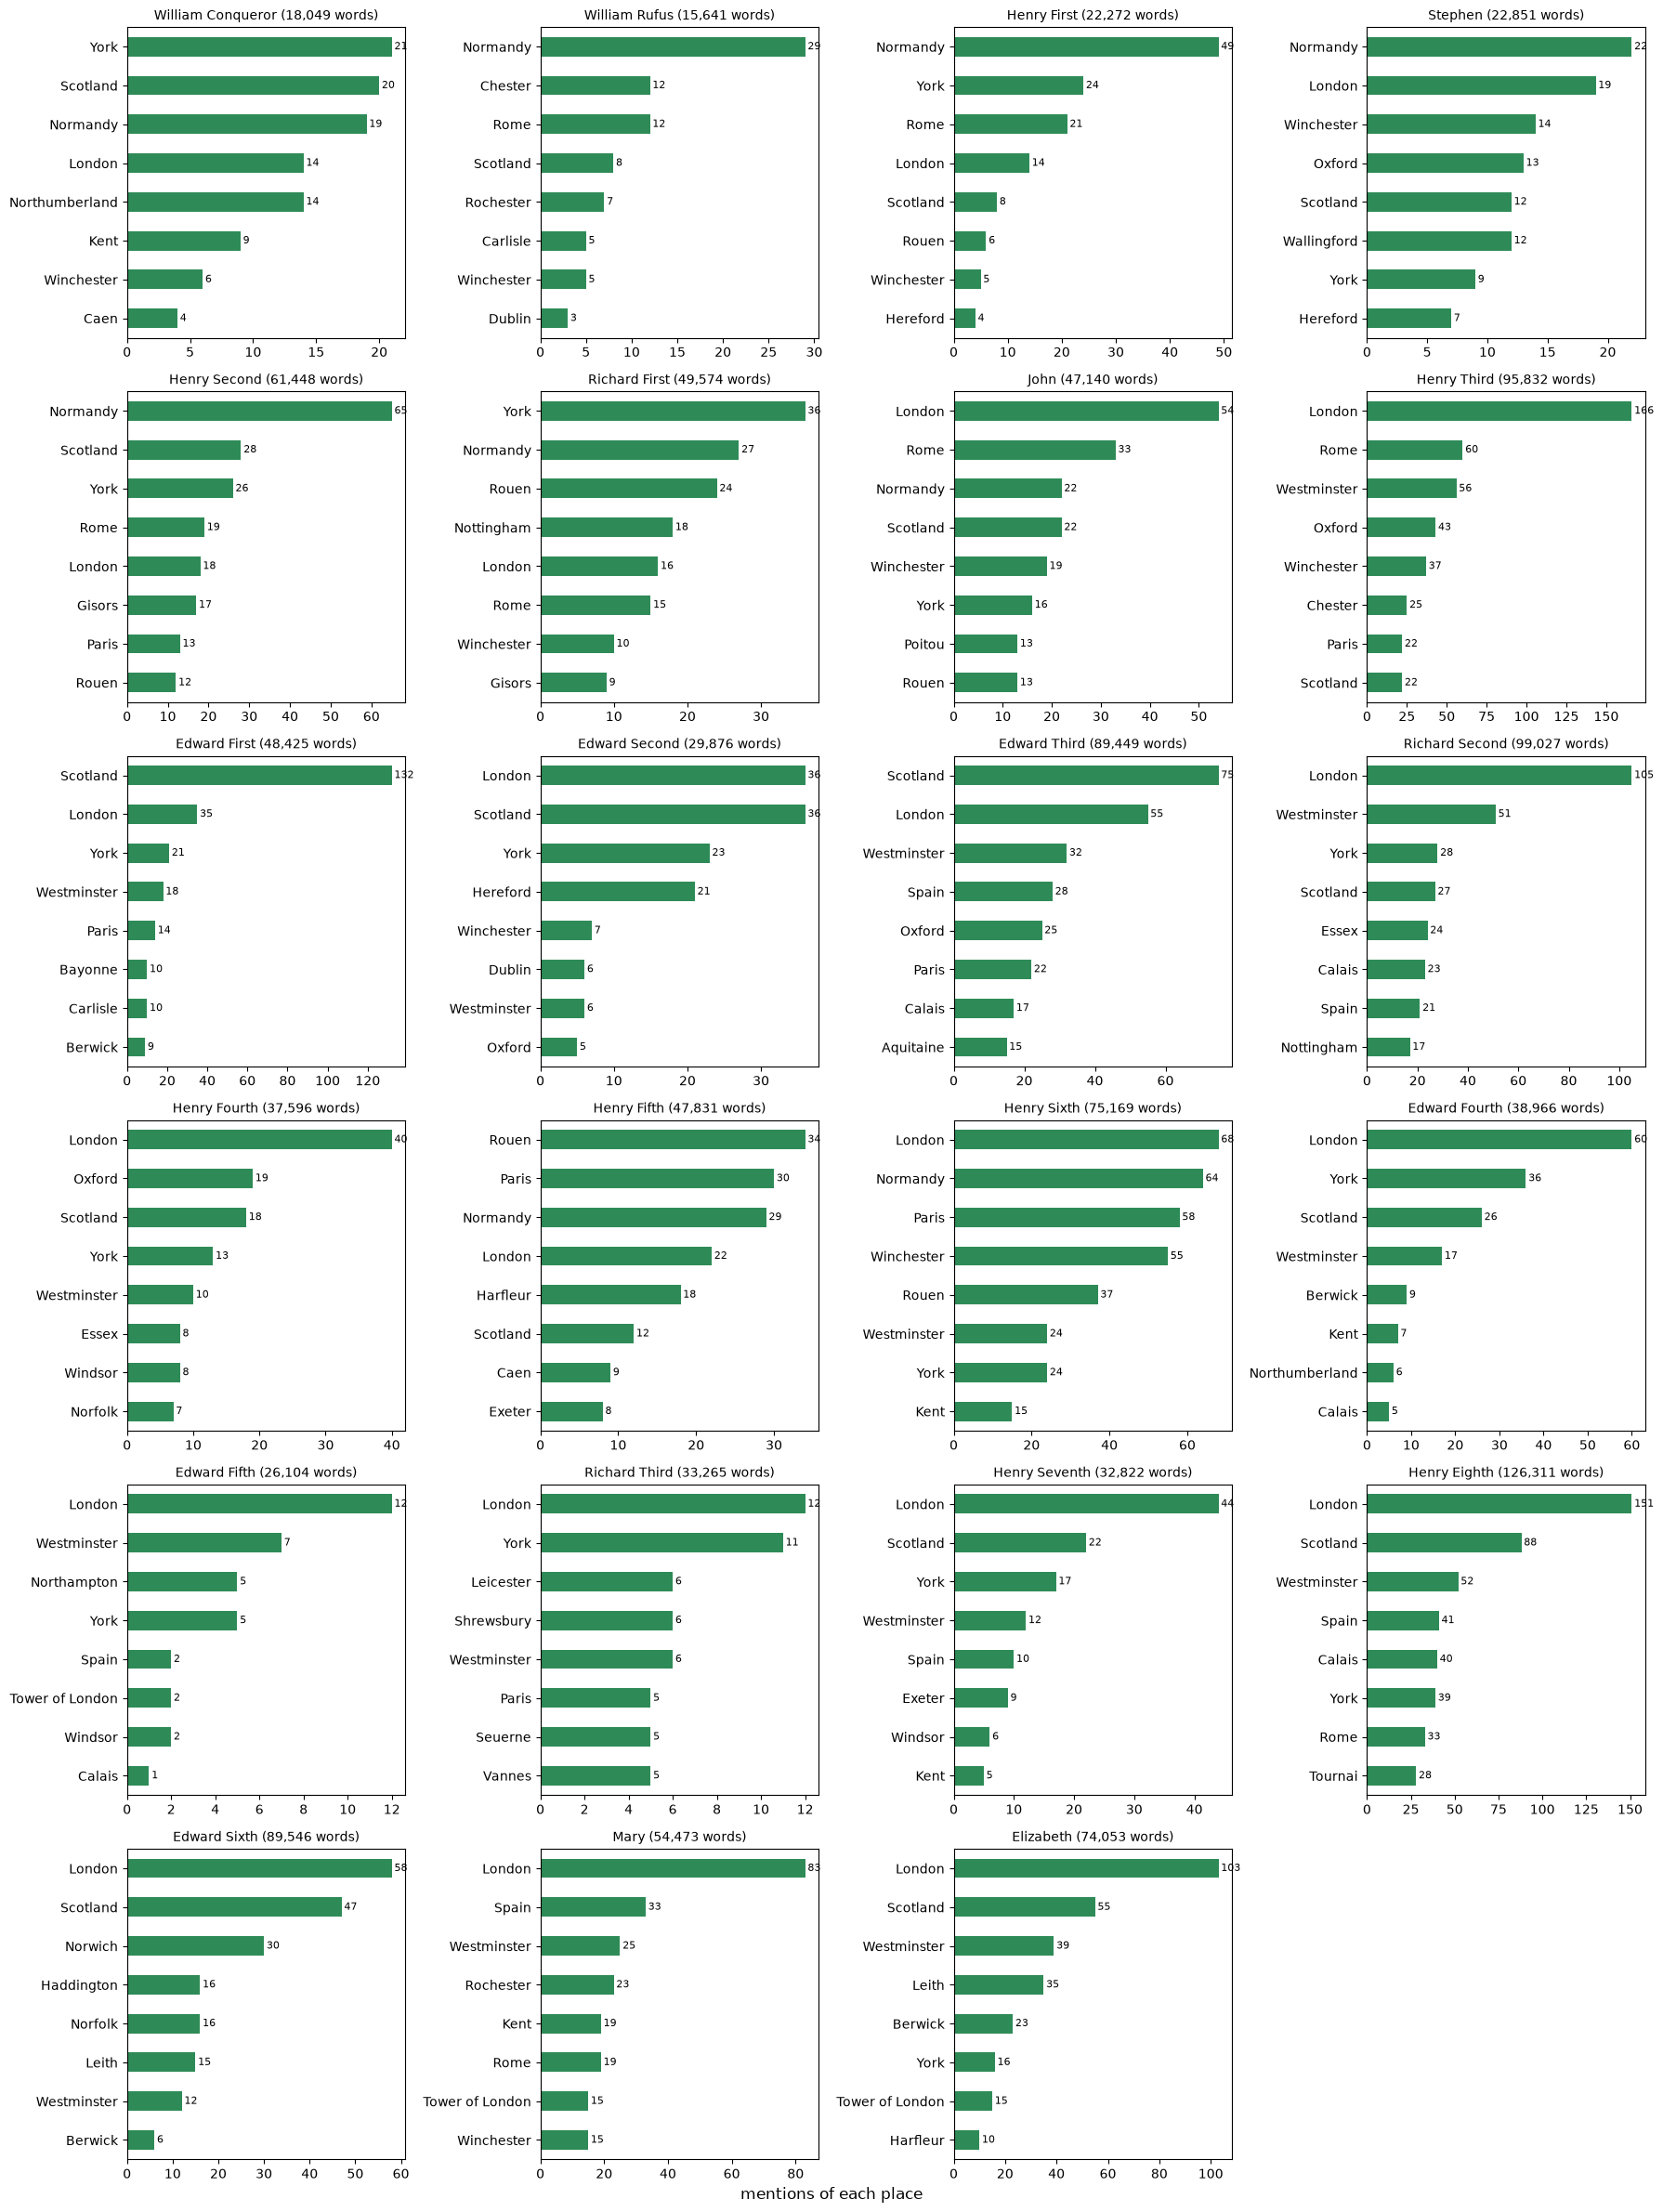

In [4]:
reigns = list(place_counts.columns)
fig, axes = plt.subplots(6, 4, figsize=(18, 24))
for ax, reign in zip(axes.flat, reigns):
    top = place_counts[reign].nlargest(8)
    top.plot.barh(ax=ax, color="seagreen")
    ax.invert_yaxis()
    ax.bar_label(ax.containers[0], padding=2, fontsize=8)
    ax.set_title(f"{reign} ({words[reign]:,} words)", fontsize=10)
    ax.set_ylabel("")
for ax in axes.flat[len(reigns):]:
    ax.axis("off")
fig.supxlabel("mentions of each place")
plt.tight_layout()
plt.show()

## 4. Place spikes by reign

A **spike** is a reign where a place is mentioned far more than usual. To compare reigns of different length, mentions are scaled to **per 10,000 words** (about 20 pages). "Times usual" = this reign's rate ÷ the place's average rate across all reigns, so 10 means ten times as often as normal.

In [5]:
# Keep places with at least 30 total mentions to reduce noise from rare names.
rate = place_counts[place_counts.sum(axis=1) >= 30] / words * 10_000

# Compare each reign's rate with the place's average across all reigns.
usual = rate.mean(axis=1)
ratio = rate.div(usual, axis=0)

# Select the 15 place–reign pairs with the largest relative spikes.
top = ratio.stack().nlargest(15)

spikes = pd.DataFrame({
    "place": top.index.get_level_values(0),
    "reign": top.index.get_level_values(1),
    "mentions": [place_counts.loc[p, r] for p, r in top.index],
    "per 10k words": [round(rate.loc[p, r], 1) for p, r in top.index],
    "usual per 10k": [round(usual[p], 1) for p, r in top.index],
    "times usual": top.values.round(0).astype(int),
})
spikes

,place,reign,mentions,per 10k words,usual per 10k,times usual
0,Leith,Elizabeth,35,4.7,0.3,14
1,Harfleur,Henry Fifth,18,3.8,0.3,12
2,Tournai,Henry Eighth,28,2.2,0.2,12
3,Gisors,Henry Second,17,2.8,0.3,10
4,Ardres,Henry Eighth,19,1.5,0.2,9
5,Northumberland,William Conqueror,14,7.8,0.9,8
6,Chester,William Rufus,12,7.7,0.9,8
7,Poitou,John,13,2.8,0.3,8
8,Carlisle,William Rufus,5,3.2,0.4,8
9,Tournai,Edward Third,13,1.5,0.2,8


### The 15 biggest spikes

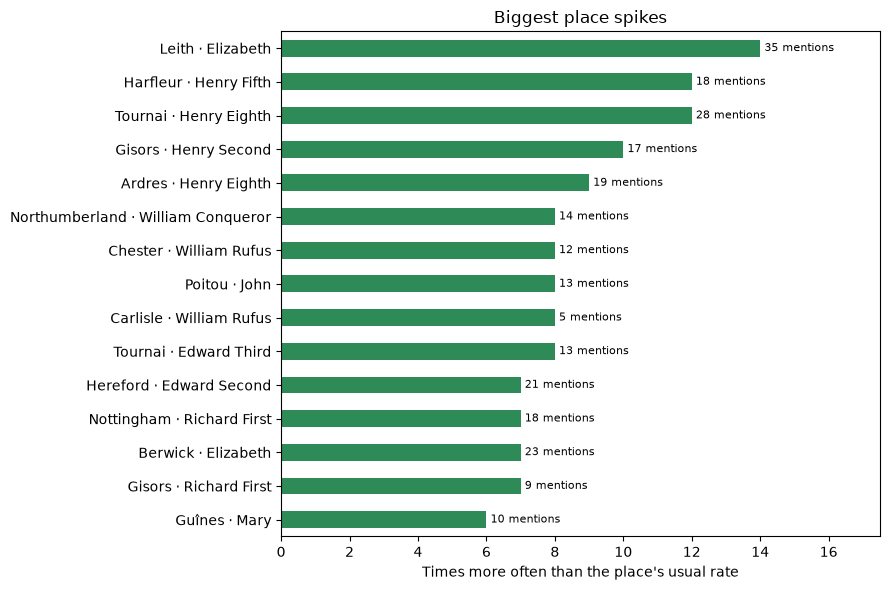

In [6]:
labels = spikes["place"] + " · " + spikes["reign"]
ax = spikes["times usual"].plot.barh(figsize=(9, 6), color="seagreen")
ax.invert_yaxis()
ax.set_yticklabels(labels)
ax.bar_label(ax.containers[0], labels=[f"{m} mentions" for m in spikes["mentions"]], padding=3, fontsize=8)
ax.set(title="Biggest place spikes", xlabel="Times more often than the place's usual rate")
ax.set_xlim(0, spikes["times usual"].max() * 1.25)
plt.tight_layout()
plt.show()

### Each spike in context

The six places with the biggest spikes, tracked across all reigns, with the spike reign marked.

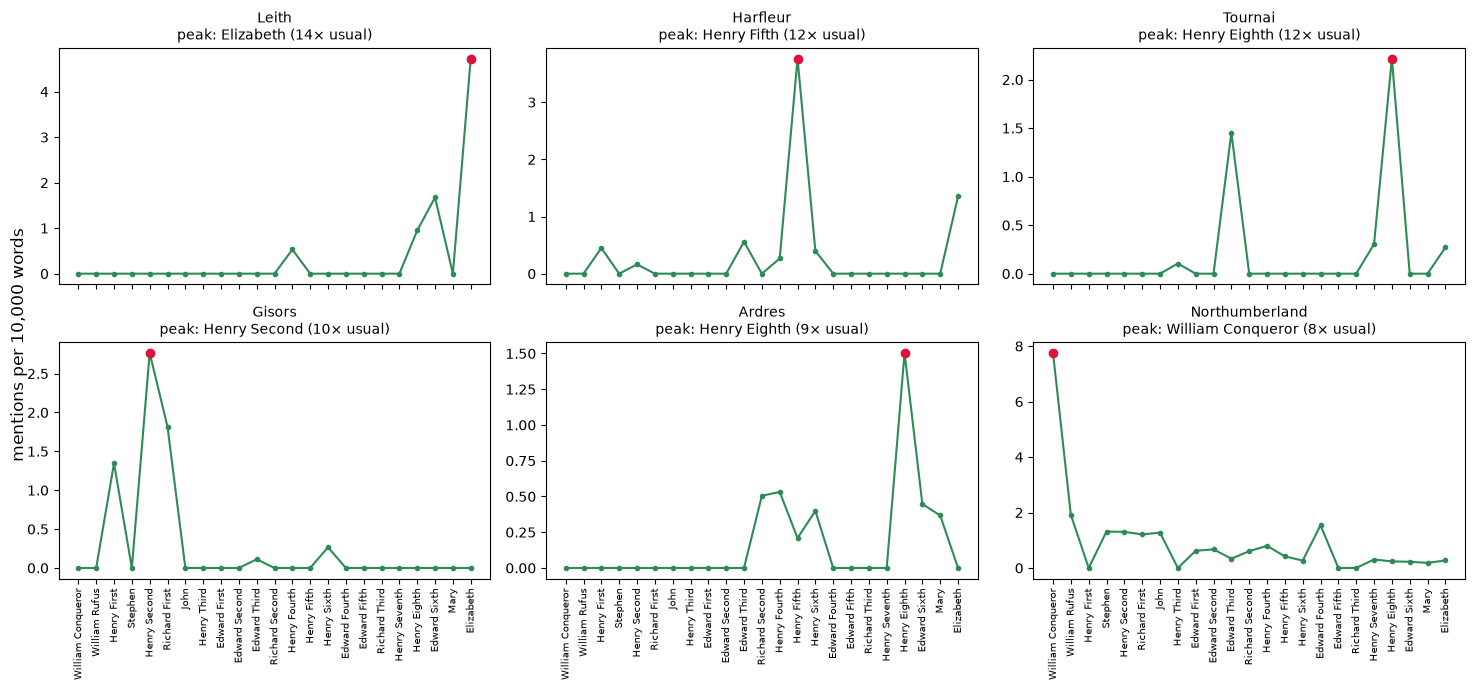

In [7]:
# Select the six distinct places with the strongest spikes.
best = spikes.drop_duplicates("place").head(6)

# Create one line chart for each place, arranged in a 2-by-3 grid.
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)

for ax, (_, s) in zip(axes.flat, best.iterrows()):
    # Plot the place's mention rate across every reign.
    ax.plot(
        range(len(rate.columns)),
        rate.loc[s["place"]],
        color="seagreen",
        marker="o",
        markersize=3,
    )

    # Highlight the reign associated with the largest spike.
    i = rate.columns.get_loc(s["reign"])
    ax.plot(
        i,
        rate.loc[s["place"], s["reign"]],
        "o",
        color="crimson",
    )

    ax.set_title(f"{s['place']}\npeak: {s['reign']} ({s['times usual']}× usual)", fontsize=10)

# Show reign names along the bottom row of plots.
for ax in axes[1]:
    ax.set_xticks(range(len(rate.columns)), rate.columns, rotation=90, fontsize=7)

fig.supylabel("mentions per 10,000 words")
plt.tight_layout()
plt.show()